In [9]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y MÓDULOS
# ==============================================================================

# Manejo y manipulación de datos en tablas (DataFrames)
import pandas as pd

# Visualización gráfica de datos (gráficos estadísticos, matriz de confusión)
import seaborn as sns
import matplotlib.pyplot as plt

# Montaje de Google Drive para acceder a archivos almacenados en la nube
from google.colab import drive
drive.mount('/content/drive')

# División de datos en conjuntos de entrenamiento y prueba
from sklearn.model_selection import train_test_split

# Algoritmos de Machine Learning (Árbol de Decisión y Random Forest)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Métricas de evaluación para modelos de clasificación
from sklearn import metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


CASO DE EJEMPLO TITANIC


Cargo, limpio y entreno modelo

In [11]:
# 1. Cargar y limpiar básico en Pandas
df = sns.load_dataset('titanic')

# Seleccionar pocas variables y rellenar nulos
df = df[['survived', 'pclass', 'sex', 'age', 'fare']].dropna()
df['sex'] = df['sex'].map({'female': 1, 'male': 0}) # Convertir a número

# 2. Separar X e y
X = df[['pclass', 'sex', 'age', 'fare']]
y = df['survived']

# 3. Split y Entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 4. Predicciones
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]



Calculo matriz de confusion y metricas

[[70 17]
 [17 39]]


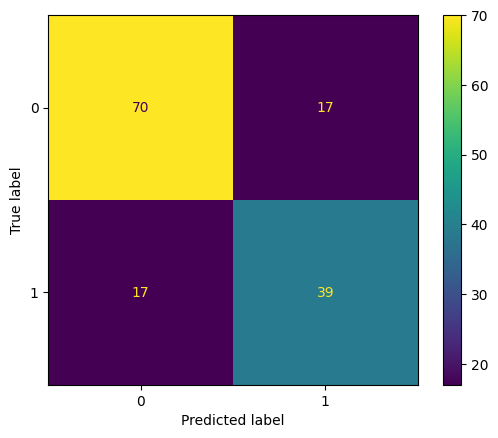

In [12]:
cm = metrics.confusion_matrix(y_test, y_pred)
print(cm)
metrics.ConfusionMatrixDisplay(confusion_matrix=cm).plot();



In [ ]:

# ---------------------------------------------------------
# 1. MÉTRICAS GLOBALES (Promedio predeterminado: binary/macro)
# ---------------------------------------------------------
# Precision: De todas las predicciones positivas, ¿cuántas fueron correctas?
precision = metrics.precision_score(y_test, y_pred)
print(f"Precision Global : {precision:.4f}")

# Recall (Sensibilidad): De todos los casos positivos reales, ¿cuántos detectamos?
recall = metrics.recall_score(y_test, y_pred)
print(f"Recall Global    : {recall:.4f}")

# F1-Score: Media armónica entre Precision y Recall (equilibrio entre ambas)
f1 = metrics.f1_score(y_test, y_pred)
print(f"F1-Score Global  : {f1:.4f}")

print("-" * 50)

# ---------------------------------------------------------
# 2. DESGLOSE DETALLADO POR CLASE
# ---------------------------------------------------------
# precision_recall_fscore_support devuelve arrays con el valor de cada métrica
# para cada clase individual, más el 'support' (cantidad de muestras reales por clase).
p, r, f, s = metrics.precision_recall_fscore_support(y_test, y_pred)

print("Métricas desglosadas por clase:")
for i, (prec, rec, f1_c, sup) in enumerate(zip(p, r, f, s)):
    print(f"  Clase {i} -> Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1_c:.4f} | Soporte: {sup}")

Precision Global : 0.6964
Recall Global    : 0.6964
F1-Score Global  : 0.6964
--------------------------------------------------
Métricas desglosadas por clase:
  Clase 0 -> Precision: 0.8046 | Recall: 0.8046 | F1: 0.8046 | Soporte: 87
  Clase 1 -> Precision: 0.6964 | Recall: 0.6964 | F1: 0.6964 | Soporte: 56


CURVA ROC


[Explicacion ROC](https://www.youtube.com/watch?v=Uyfcqn3Nidc)

In [ ]:


dt = DecisionTreeClassifier(max_depth=4)
model = dt.fit(X_train, y_train)

# Obtener las probabilidades y seleccionar solo la columna de la clase positiva (clase 1)
probs = model.predict_proba(X_test)[:, 1]  # <--- Agrega [:, 1] aquí

# Calcula la curva ROC
fpr, tpr, thresholds = roc_curve(y_test, probs)

# Calcula el área bajo la curva (AUC)
roc_auc = auc(fpr, tpr)

print(f"Área bajo la curva ROC (AUC): {roc_auc:.4f}")

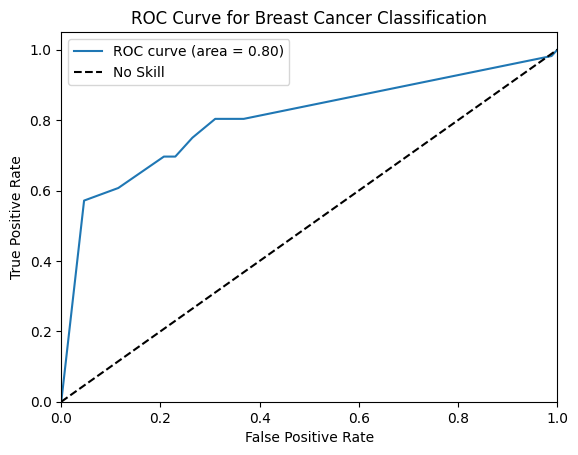

In [ ]:
# Para graficar la curva ROC
probs = model.predict_proba(X_test)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], 'k--', label='No Skill')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Breast Cancer Classification')
plt.legend()
plt.show()

# PRACTICA CON GLASS

Mounted at /content/drive


In [13]:

# Definición de los nombres de columnas
column_names = [
    'id',
    'RI',
    'Na',
    'Mg',
    'Al',
    'Si',
    'K',
    'Ca',
    'Ba',
    'Fe',
    'glass_type'
]


# Visualización rápida

df=pd.read_csv("/content/drive/MyDrive/1) UNIVERSIDAD/2) Ciencia de Datos/3er año/Mineria de datos/datasets/glass.csv", header=None, names=column_names)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          214 non-null    int64  
 1   RI          214 non-null    float64
 2   Na          214 non-null    float64
 3   Mg          214 non-null    float64
 4   Al          214 non-null    float64
 5   Si          214 non-null    float64
 6   K           214 non-null    float64
 7   Ca          214 non-null    float64
 8   Ba          214 non-null    float64
 9   Fe          214 non-null    float64
 10  glass_type  214 non-null    int64  
dtypes: float64(9), int64(2)
memory usage: 18.5 KB


In [15]:
df.head()

,id,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,glass_type
0,1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,4,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,5,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


1. Utilice la base de datos “glass”, separando en 90-10.
Calcule e imprima la matriz de confusión.
Calcule e imprima accuracy, precision, recall, f-score y AUC-ROC.
Repita los cálculos 10 veces, cambiando el random_state en el split. Calcule el
promedio e IC_95% de cada métrica.

=== MATRIZ DE CONFUSIÓN ACUMULADA (10 ITERACIONES) ===
    1   2  3  5  6   7
1  63   6  1  0  0   0
2  12  64  1  0  3   0
3   9   2  9  0  0   0
5   0   3  0  6  0   1
6   0   1  0  0  9   0
7   1   1  0  0  0  28

=== RESUMEN DE MÉTRICAS CON IC 95% ===
  Métrica  Promedio  Desv. Est. Formato (Mean ± IC)
 ACCURACY  0.813636    0.075606     0.8136 ± 0.0541
PRECISION  0.804921    0.090402     0.8049 ± 0.0647
   RECALL  0.813636    0.075606     0.8136 ± 0.0541
       F1  0.797617    0.084027     0.7976 ± 0.0601
  AUC-ROC  0.952364    0.036396     0.9524 ± 0.0260


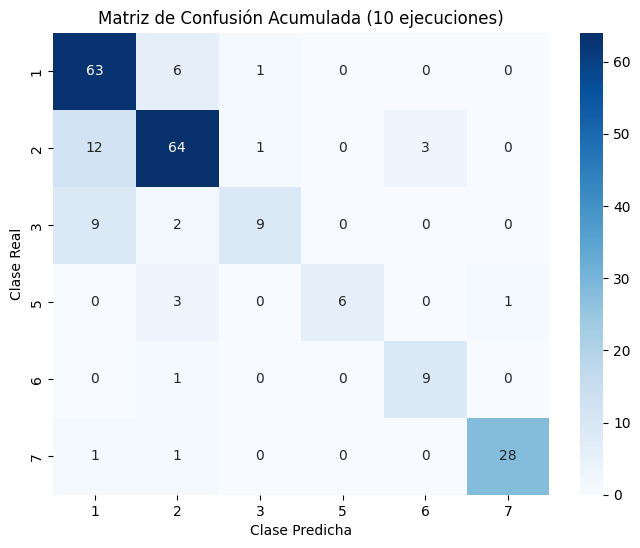

In [16]:
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Separar variables predictoras (X) y target (y)
X = df.drop(columns=['id', 'glass_type'])
y = df['glass_type']

# ==============================================================================
# 2. EXPERIMENTO CON 10 SEMILLAS (SPLIT 90-10)
# ==============================================================================

# Lista de 10 semillas distintas
seeds = [0, 12, 42, 100, 123, 777, 999, 1234, 2024, 9999]

# Diccionario para almacenar el historial de métricas
results = {
    'accuracy': [],
    'precision': [],
    'recall': [],
    'f1': [],
    'auc_roc': []
}

# Matriz de confusión acumulativa
unique_classes = np.unique(y)
cm_total = np.zeros((len(unique_classes), len(unique_classes)), dtype=int)

for seed in seeds:
    # Separación 90% entrenamiento y 10% prueba
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.10, random_state=seed, stratify=y
    )

    # Entrenamiento del modelo
    model = RandomForestClassifier(n_estimators=100, random_state=seed)
    model.fit(X_train, y_train)

    # Predicciones
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    # Acumular matriz de confusión de la iteración
    cm_iter = confusion_matrix(y_test, y_pred, labels=unique_classes)
    cm_total += cm_iter

    # Cálculo de métricas por iteración
    results['accuracy'].append(accuracy_score(y_test, y_pred))
    results['precision'].append(precision_score(y_test, y_pred, average='weighted', zero_division=0))
    results['recall'].append(recall_score(y_test, y_pred, average='weighted', zero_division=0))
    results['f1'].append(f1_score(y_test, y_pred, average='weighted', zero_division=0))

    # AUC-ROC Multiclase One-vs-Rest (ponderado)
    auc = roc_auc_score(y_test, y_proba, multi_class='ovr', average='weighted', labels=unique_classes)
    results['auc_roc'].append(auc)

# ==============================================================================
# 3. CÁLCULO DE PROMEDIOS E INTERVALOS DE CONFIANZA 95%
# ==============================================================================

summary_data = []
n = len(seeds)
confidence = 0.95

for metric_name, values in results.items():
    mean_val = np.mean(values)
    std_err = stats.sem(values)  # Error estándar de la media (std / sqrt(n))

    # Margen de error usando distribución t de Student con (n-1) grados de libertad
    h = std_err * stats.t.ppf((1 + confidence) / 2., n - 1)

    summary_data.append({
        'Métrica': metric_name.upper().replace('_', '-'),
        'Promedio': mean_val,
        'Desv. Est.': np.std(values, ddof=1),
        'IC_95% Inferior': mean_val - h,
        'IC_95% Superior': mean_val + h,
        'Formato (Mean ± IC)': f"{mean_val:.4f} ± {h:.4f}"
    })

df_summary = pd.DataFrame(summary_data)

# ==============================================================================
# 4. IMPRESIÓN DE RESULTADOS
# ==============================================================================

print("=== MATRIZ DE CONFUSIÓN ACUMULADA (10 ITERACIONES) ===")
print(pd.DataFrame(cm_total, index=unique_classes, columns=unique_classes))

print("\n=== RESUMEN DE MÉTRICAS CON IC 95% ===")
print(df_summary[['Métrica', 'Promedio', 'Desv. Est.', 'Formato (Mean ± IC)']].to_string(index=False))

# Gráfico de la Matriz de Confusión Acumulada
plt.figure(figsize=(8, 6))
sns.heatmap(cm_total, annot=True, fmt='d', cmap='Blues',
            xticklabels=unique_classes, yticklabels=unique_classes)
plt.title('Matriz de Confusión Acumulada (10 ejecuciones)')
plt.xlabel('Clase Predicha')
plt.ylabel('Clase Real')
plt.show()